# Campaign Network Analysis - Clean Version
**Dataset:** 420 posts, 251 accounts, prayforkalimantan campaign

**Findings:** Data organik, bukan buzzer coordinated attack. Analisis fokus ke network structure & influencer identification.

## 1. Setup & Data Loading

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Config
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("Libraries loaded")

Libraries loaded


In [ ]:
df = pd.read_csv("../data/processed/RoySuryo/standardized_data.csv")
df["date"] = pd.to_datetime(df["date"])

for col in ["account_id", "post_id", "target_account_id", "target_post_id"]:
    if col in df.columns:
        df[col] = df[col].astype(str).replace("nan", pd.NA)

print(f"Loaded: {len(df)} posts from {df['account_id'].nunique()} accounts")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
df.head()

Loaded: 1514 posts from 1007 accounts
Date range: 2026-08-08 09:53:16+00:00 to 2026-11-08 07:09:47+00:00


,post_id,account_id,id,user_id,source_post_id,source_account_id,target_post_id,target_account_id,target_username,relation_type,mentioned_user_ids,date,text,url,conversation_id,username,created,followers,following,statuses,bio,avatar,is_rt,is_reply,is_quote,isu,query
0,2119321404298645606,1810223652115484672,2119321404298645606,1810223652115484672,2119321404298645606,1810223652115484672,2.1193019361595474e+18,424908793.0,Opposite6888,reply,"[""424908793"", ""2108414365057814528""]",2026-11-08 06:49:32+00:00,@Opposite6888 @SuyudiArioSeto Sjk skandal ini ...,https://x.com/WempiF90099/status/2119321404298...,2119301936159547431,WempiF90099,2024-07-08T08:06:03Z,64,12,1376,Akun ke-3. Pengamat MotoGP-Netizens dan Pers. ...,https://pbs.twimg.com/profile_images/210314333...,False,True,False,wowo2,https://x.com/search?q=prabowo%20teddy&src=typ...
1,2119309075242713388,2054833974577602560,2119309075242713388,2054833974577602560,2119309075242713388,2054833974577602560,<NA>,<NA>,NaN,original,[],2026-11-08 06:00:33+00:00,Kabarnya gibran bentar lagi akan dimakzulkan.....,https://x.com/Uniliswara0/status/2119309075242...,2119309075242713388,Uniliswara0,2026-05-14T08:01:03Z,20115,8252,21464,NaN,https://pbs.twimg.com/profile_images/205550801...,False,False,False,wowo2,https://x.com/search?q=prabowo%20teddy&src=typ...
2,2119295578949701742,2108908455482503168,2119295578949701742,2108908455482503168,2119295578949701742,2108908455482503168,2.1192946960277834e+18,1.247561996528214e+18,yellbooks,reply,"[""1247561996528214016""]",2026-11-08 05:06:55+00:00,"@yellbooks masa bawa prabowo, yang ada digebuk...",https://x.com/__morvic/status/2119295578949701742,2119282755834171617,__morvic,2026-10-10T13:14:10Z,30,31,1072,"homophobic, zionist, 02 voters dni.",https://pbs.twimg.com/profile_images/211724476...,False,True,False,wowo2,https://x.com/search?q=prabowo%20teddy&src=typ...
3,2119282468734058548,243998004,2119282468734058548,243998004,2119282468734058548,243998004,2.119033652709675e+18,1.4377503267071918e+18,MiskinTV_,reply,"[""1437750326707191812""]",2026-11-08 04:14:49+00:00,"@MiskinTV_ Yg abdi negara cuma teddy, lainnya ...",https://x.com/Ar_910/status/2119282468734058548,2119033652709675086,Ar_910,2011-01-28T08:11:57Z,170,171,16103,mengabdi sepenuh hati,https://pbs.twimg.com/profile_images/195086238...,False,True,False,wowo2,https://x.com/search?q=prabowo%20teddy&src=typ...
4,2119276834814820598,1275361811060019201,2119276834814820598,1275361811060019201,2119276834814820598,1275361811060019201,2.119246161404207e+18,1.0403069641006694e+18,NenkMonica,reply,"[""1040306964100669440""]",2026-11-08 03:52:26+00:00,"@NenkMonica Ketika nyebrang ke kubu Jokowi, me...",https://x.com/BuchroniK/status/211927683481482...,2119246161404207174,BuchroniK,2020-06-23T09:35:35Z,1477,755,49642,IT Business Development.\n😊🙏😊,https://pbs.twimg.com/profile_images/194415489...,False,True,False,wowo2,https://x.com/search?q=prabowo%20teddy&src=typ...


## 2. Feature Engineering

In [15]:
df["hashtags"] = df["text"].str.findall(r"#\w+")
df["n_tags"] = df["hashtags"].str.len()

df["body_clean"] = df["text"].str.replace(r"^(@\w+\s*)+", "", regex=True).str.strip()
df["body_len"] = df["body_clean"].str.len()

df["has_url"] = df["text"].str.contains(r"https?://", regex=True)

print("Features extracted:")
print(df[["n_tags", "body_len", "has_url"]].describe())

Features extracted:
            n_tags     body_len
count  1514.000000  1514.000000
mean      0.285337   272.796565
std       1.132566   405.599990
min       0.000000     3.000000
25%       0.000000    82.250000
50%       0.000000   161.000000
75%       0.000000   279.000000
max      12.000000  4668.000000


## 3. Account-Level Analysis

In [16]:
accounts = df.groupby("account_id").agg(
    username=("username", "first"),
    n_posts=("post_id", "count"),
    avg_tags=("n_tags", "mean"),
    avg_body_len=("body_len", "mean"),
    n_replies=("is_reply", "sum"),
    n_quotes=("is_quote", "sum"),
    n_originals=("relation_type", lambda x: (x == "original").sum()),
    first_post=("date", "min"),
    last_post=("date", "max"),
    followers=("followers", "first"),
    following=("following", "first")
).reset_index()

accounts["active_hours"] = (accounts["last_post"] - accounts["first_post"]).dt.total_seconds() / 3600
accounts["post_rate"] = accounts["n_posts"] / (accounts["active_hours"] + 0.1)

print(f"Total accounts: {len(accounts)}")
accounts.describe()

Total accounts: 1007


,n_posts,avg_tags,avg_body_len,n_replies,n_quotes,n_originals,followers,following,active_hours,post_rate
count,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1.007000e+03,1007.000000,1007.000000,1007.000000
mean,1.503476,0.135811,201.952094,0.495531,0.217478,0.790467,5.590732e+04,1638.274081,95.969879,8.511148
std,2.082717,0.662115,301.833509,0.714609,0.584230,2.021453,4.470462e+05,2922.988257,337.190327,3.590330
min,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.001183
25%,1.000000,0.000000,72.000000,0.000000,0.000000,0.000000,8.450000e+01,128.000000,0.000000,10.000000
50%,1.000000,0.000000,130.000000,0.000000,0.000000,0.000000,5.330000e+02,424.000000,0.000000,10.000000
75%,1.000000,0.000000,237.000000,1.000000,0.000000,1.000000,4.194500e+03,1644.000000,0.000000,10.000000
max,34.000000,5.000000,3798.000000,9.000000,7.000000,34.000000,8.743047e+06,31392.000000,2181.643333,18.136020


In [17]:
influencers = accounts[
    (accounts["n_posts"] >= 10) | 
    ((accounts["followers"] > 1000) & (accounts["n_posts"] >= 5))
].sort_values("n_posts", ascending=False)

print(f"Influencers: {len(influencers)}")
print(influencers[["username", "n_posts", "avg_tags", "followers", "post_rate"]].head(10))

Influencers: 28
          username  n_posts  avg_tags  followers  post_rate
477  LambeSahamjja       34  0.000000     105207   0.017094
153  Franken_blues       24  0.000000      21481   0.013515
113     Heraloebss       24  0.000000     175781   0.011000
900       Metro_TV       20  4.650000    8743047   0.009289
86       sundarese       16  0.000000      16083   0.033049
779      kompascom       16  3.687500    8056535   0.007497
534    tomatskillo       14  0.357143      18402   0.009105
615   jurnalkencan       12  0.000000        183   0.015649
799      ferrykoto       12  0.000000      48909   0.005853
388    naturemood_       10  0.700000       6546   0.020605


## 4. Network Analysis

In [18]:
edges = df[df["relation_type"].isin(["reply", "quote"])]
edges = edges[["account_id", "username", "target_account_id", "target_username", "relation_type"]].dropna(subset=["target_account_id"])

G = nx.from_pandas_edgelist(
    edges, "account_id", "target_account_id",
    edge_attr=["relation_type"], create_using=nx.DiGraph()
)

print(f"Network: {len(G.nodes())} nodes, {len(G.edges())} edges")
print(f"Density: {nx.density(G):.4f}")

in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())
pagerank = nx.pagerank(G)

username_map = df[["account_id", "username"]].drop_duplicates().set_index("account_id")["username"].to_dict()
target_username_map = edges[["target_account_id", "target_username"]].drop_duplicates().set_index("target_account_id")["target_username"].to_dict()
username_map.update(target_username_map)

accounts["in_degree"] = accounts["account_id"].map(in_deg).fillna(0)
accounts["out_degree"] = accounts["account_id"].map(out_deg).fillna(0)
accounts["pagerank"] = accounts["account_id"].map(pagerank).fillna(0)

print("\n=== HIGH TARGETS (>5 mentions) ===")
high_targets = [(n, in_deg[n], username_map.get(n, str(n)[-8:])) for n in G.nodes() if in_deg[n] > 5]
high_targets.sort(key=lambda x: x[1], reverse=True)
for acc_id, deg, username in high_targets:
    print(f"@{username}: {deg} mentions")

print("\n=== HIGH ENGAGERS (>5 replies/quotes) ===")
high_engagers = [(n, out_deg[n], username_map.get(n, str(n)[-8:])) for n in G.nodes() if out_deg[n] > 5]
high_engagers.sort(key=lambda x: x[1], reverse=True)
for acc_id, deg, username in high_engagers:
    print(f"@{username}: {deg} interactions")

Network: 1089 nodes, 697 edges
Density: 0.0006

=== HIGH TARGETS (>5 mentions) ===
@LambeSahamjja: 22 mentions
@indepenSumatera: 10 mentions
@txtdrimedia: 9 mentions
@msaid_didu: 8 mentions
@Uniliswara0: 7 mentions

=== HIGH ENGAGERS (>5 replies/quotes) ===
@jurnalkencan: 12 interactions
@ferrykoto: 8 interactions


## 5. Network Visualization

Saved: output/campaign_network.png


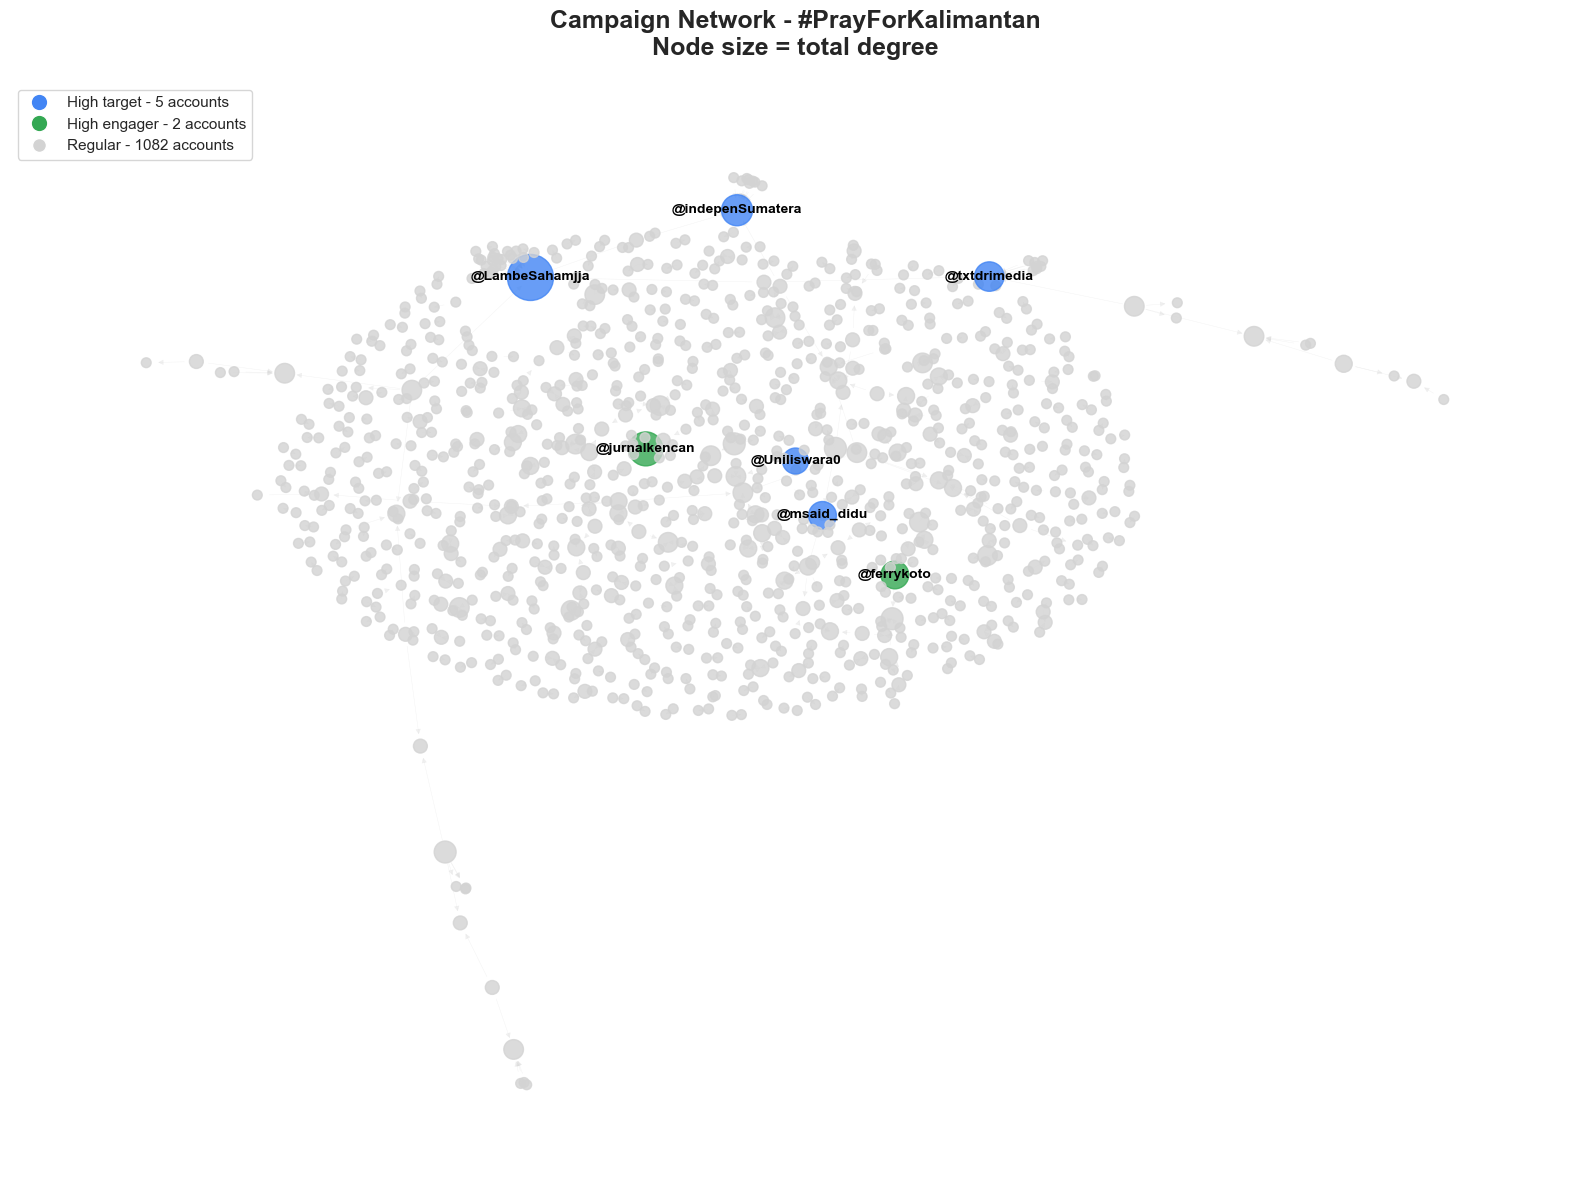

In [19]:
node_colors = []
for n in G.nodes():
    if in_deg[n] > 5:  # High target
        node_colors.append("#4285f4")  
    elif out_deg[n] > 5:  # High engager
        node_colors.append("#34a853") 
    else:
        node_colors.append("#d3d3d3")  

node_sizes = [max(50, (in_deg[n] + out_deg[n]) * 50) for n in G.nodes()]

pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)

fig, ax = plt.subplots(figsize=(16, 12))
nx.draw_networkx_edges(G, pos, edge_color="lightgray", 
                       arrows=True, arrowsize=8, width=0.3, alpha=0.3, ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, 
                       node_size=node_sizes, alpha=0.8, ax=ax)

important = [n for n in G.nodes() if in_deg[n] > 5 or out_deg[n] > 5]
labels = {n: f"@{username_map.get(n, str(n)[-8:])}" for n in important}
nx.draw_networkx_labels(G, pos, labels, font_size=10, font_weight="bold", ax=ax)

from matplotlib.lines import Line2D
legend = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#4285f4', 
           markersize=12, label=f'High target - {len([n for n in G.nodes() if in_deg[n] > 5])} accounts'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#34a853', 
           markersize=12, label=f'High engager - {len([n for n in G.nodes() if out_deg[n] > 5])} accounts'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='lightgray', 
           markersize=10, label=f'Regular - {len([n for n in G.nodes() if in_deg[n] <= 5 and out_deg[n] <= 5])} accounts')
]
ax.legend(handles=legend, loc='upper left', fontsize=11)
ax.set_title("Campaign Network - #PrayForKalimantan\nNode size = total degree", 
             fontsize=18, fontweight='bold', pad=20)
ax.axis('off')

import os
os.makedirs("../output", exist_ok=True)
plt.tight_layout()
plt.savefig("../output/campaign_network.png", dpi=200, bbox_inches="tight", facecolor='white')
print("Saved: output/campaign_network.png")
plt.show()

## 6. Temporal Analysis

Saved: output/temporal_activity.png


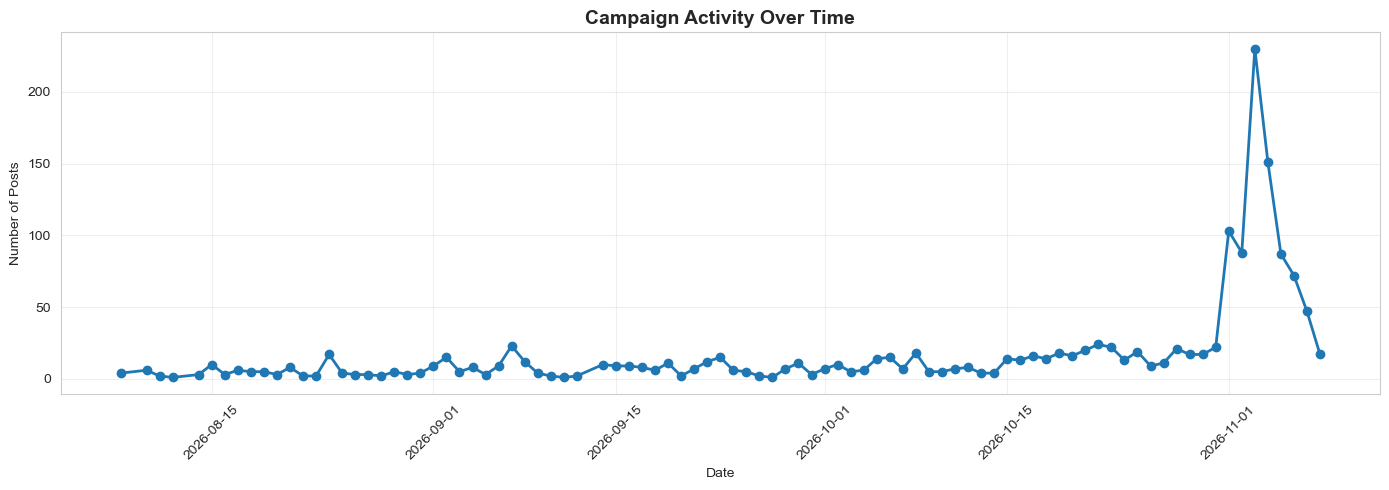

In [20]:
df["date_only"] = df["date"].dt.date
daily = df.groupby("date_only").size().reset_index(name="n_posts")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily["date_only"], daily["n_posts"], marker='o', linewidth=2)
ax.set_title("Campaign Activity Over Time", fontsize=14, fontweight='bold')
ax.set_xlabel("Date")
ax.set_ylabel("Number of Posts")
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../output/temporal_activity.png", dpi=150, bbox_inches="tight")
print("Saved: output/temporal_activity.png")
plt.show()

## 7. Export Results

In [ ]:
import os
os.makedirs("../data/features", exist_ok=True)
os.makedirs("../output", exist_ok=True)

# Save features
df.to_csv("../data/features/roysuryposts_with_features.csv", index=False)
accounts.to_csv("../data/features/account_features.csv", index=False)

print("Saved:")
print("  - data/features/posts_with_features.csv")
print("  - data/features/account_features.csv")
print("\nNext step: Text embedding with IndoBERTweet (notebook 03)")

Saved:
  - data/features/posts_with_features.csv
  - data/features/account_features.csv

Next step: Text embedding with IndoBERTweet (notebook 03)
